# Занятие 4. Базовые преобразования изображений
## Размер, цвет, яркость, контраст

**Часть 1** — демонстрация преподавателя.  
**Часть 2** — самостоятельные операции по 1–2 строки в `# YOUR CODE HERE`.

## Часть 1. Демонстрация преподавателя

После каждой операции спрашиваем: **что изменилось в массиве и что сохранилось в изображении?**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.datasets import load_sample_image

plt.rcParams['figure.figsize'] = (8, 4)
image = load_sample_image('china.jpg')
pil = Image.fromarray(image)
H, W = image.shape[:2]
print('shape:', image.shape, 'dtype:', image.dtype)

shape: (427, 640, 3) dtype: uint8


### 1. Resize: меняем H и W
Сохраним отношение сторон и уменьшим картинку в два раза.

до: (427, 640, 3) после: (213, 320, 3)


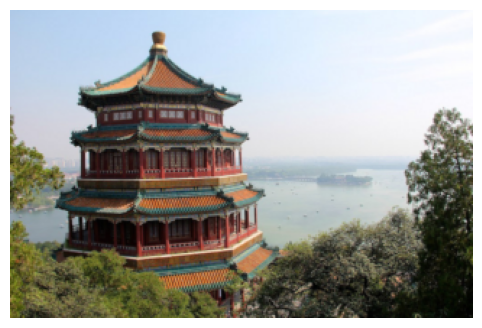

In [2]:
half = np.array(pil.resize((W // 2, H // 2), Image.Resampling.BILINEAR))
print('до:', image.shape, 'после:', half.shape)
plt.imshow(half); plt.axis('off'); plt.show()

### 2. Если нарушить отношение сторон, объект искажается
Сравним корректное уменьшение и намеренно «сплющенную» версию.

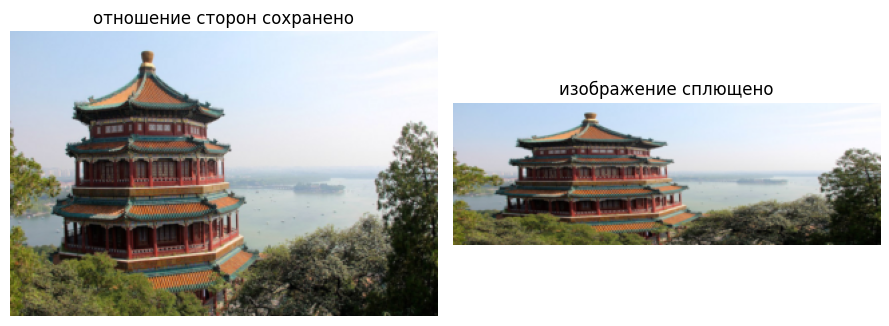

In [3]:
squashed = np.array(pil.resize((W // 2, H // 4), Image.Resampling.BILINEAR))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(half); axes[0].set_title('отношение сторон сохранено')
axes[1].imshow(squashed); axes[1].set_title('изображение сплющено')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

### 3. Crop: выбираем область без интерполяции
Возьмём центральную часть массива.

crop: (214, 320, 3)


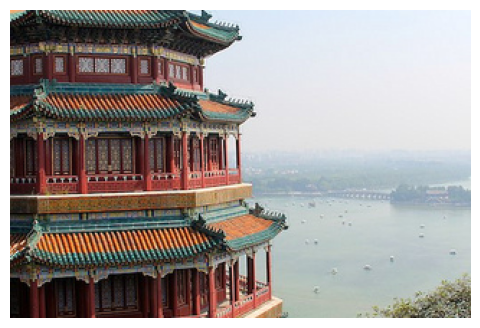

In [4]:
crop = image[H//4:3*H//4, W//4:3*W//4]
print('crop:', crop.shape)
plt.imshow(crop); plt.axis('off'); plt.show()

### 4. RGB → grayscale
Пространственный размер сохраняется, но вместо трёх цветовых компонент остаётся одна яркость.

(427, 640, 3) -> (427, 640)


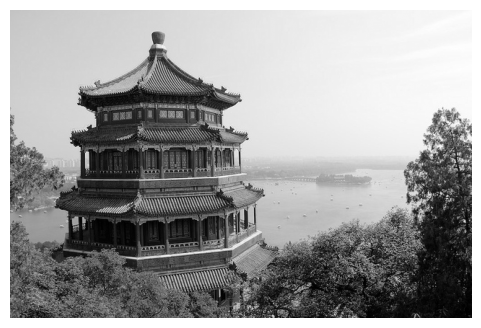

In [5]:
gray = np.array(pil.convert('L'))
print(image.shape, '->', gray.shape)
plt.imshow(gray, cmap='gray', vmin=0, vmax=255); plt.axis('off'); plt.show()

### 5. Яркость: умножаем значения и ограничиваем диапазон
Сначала переводим в float, затем `clip`, потом возвращаем `uint8`.

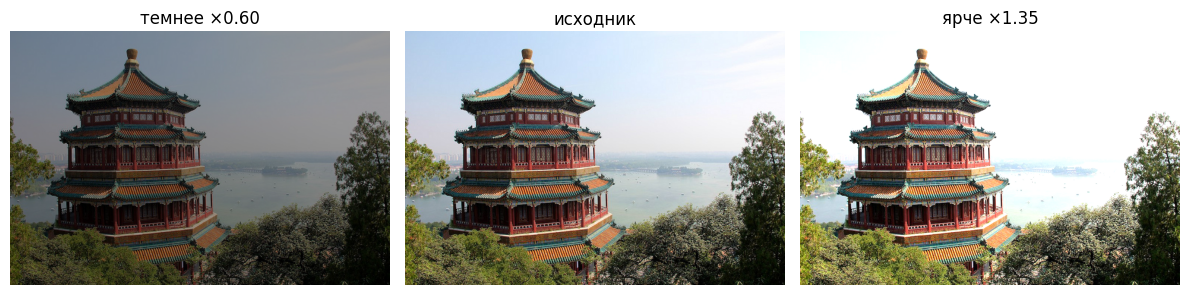

In [6]:
bright = np.clip(image.astype(np.float32) * 1.35, 0, 255).astype(np.uint8)
dark = np.clip(image.astype(np.float32) * 0.60, 0, 255).astype(np.uint8)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, title in zip(axes, [dark, image, bright], ['темнее ×0.60', 'исходник', 'ярче ×1.35']):
    ax.imshow(img); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()

### 6. Контраст: отдаляем значения от среднего уровня
Используем 128 как простой центральный уровень для `uint8`.

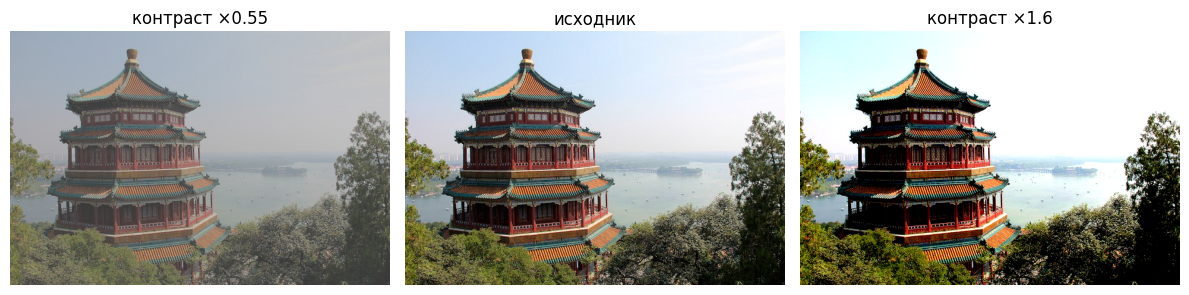

In [7]:
contrast = np.clip((image.astype(np.float32) - 128) * 1.6 + 128, 0, 255).astype(np.uint8)
low_contrast = np.clip((image.astype(np.float32) - 128) * 0.55 + 128, 0, 255).astype(np.uint8)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, title in zip(axes, [low_contrast, image, contrast], ['контраст ×0.55', 'исходник', 'контраст ×1.6']):
    ax.imshow(img); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()

### 7. Из-за `clip` часть деталей может потеряться
Посчитаем пиксели, у которых после осветления хотя бы один канал дошёл до 255.

In [8]:
saturated = np.any(bright == 255, axis=2)
print('Пикселей с насыщенным каналом:', saturated.sum())
print('Доля:', saturated.mean())

Пикселей с насыщенным каналом: 131533
Доля: 0.48131220725995316


---
## Часть 2. Самостоятельные мини-задачи

Работаем с уже загруженными `image`, `pil`, `H`, `W`.

### Задание 1. Уменьшите изображение в два раза
Создайте `small` через Pillow и bilinear interpolation.

In [9]:
# YOUR CODE HERE (1 строка)
# small = ...

### Задание 2. Вырежьте центральную половину
Создайте `center_crop` размером примерно H/2 × W/2.

In [10]:
# YOUR CODE HERE (1 строка)
# center_crop = ...

### Задание 3. Сделайте grayscale
Создайте двумерный массив `gray_s`.

In [11]:
# YOUR CODE HERE (1 строка)
# gray_s = ...

### Задание 4. Сделайте изображение ярче
Коэффициент 1.25, с `float32`, `clip` и возвратом к `uint8`.

In [12]:
# YOUR CODE HERE (1 строка)
# bright_s = ...

### Задание 5. Сделайте изображение темнее
Коэффициент 0.7.

In [13]:
# YOUR CODE HERE (1 строка)
# dark_s = ...

### Задание 6. Увеличьте контраст
Коэффициент 1.5 вокруг уровня 128.

In [14]:
# YOUR CODE HERE (1–2 строки)
# contrast_s = ...

### Задание 7. Посчитайте насыщенные пиксели
Сколько пикселей `bright_s` имеют хотя бы один канал 255? Запишите число в `n_saturated`.

In [15]:
# YOUR CODE HERE (1 строка)
# n_saturated = ...

### Задание 8. Проверьте shape
Создайте кортеж `shapes = (image.shape, small.shape, center_crop.shape, gray_s.shape)`.

In [16]:
# YOUR CODE HERE (1 строка)
# shapes = ...

### Мини-вопрос
Какие из сегодняшних операций меняют пространственный размер, какие — число каналов, а какие оставляют shape прежним, но меняют значения?